# 02 - Feature-Selection Experiments
### ActivitySense AI | Yash Rajput - 2427010652

Compare four feature groups: **full (561)**, **accelerometer**, **gyroscope**, and a
**reduced** subset (SelectKBest, mutual information). Results come from `src/train.py`.

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt

In [2]:
from src.data_loader import load_train, load_features
from src.feature_selection import get_feature_groups
from src import config as C, visualize as V

Xtr, ytr, ytr_name, _ = load_train()
feats = load_features()
groups = get_feature_groups(Xtr, ytr_name, feats, k=C.SELECTK)
print("Feature-group sizes:", {k: len(v) for k, v in groups.items()})

Feature-group sizes: {'full': 561, 'accelerometer': 350, 'gyroscope': 213, 'reduced': 50}


## Experiment results (from the trained pipeline)

In [3]:
m = pd.read_csv(C.RESULTS_DIR / "metrics.csv")
pivot = m.pivot(index="feature_group", columns="model", values="accuracy").reindex(
    ["full", "accelerometer", "gyroscope", "reduced"])
pivot.round(3)

model,knn,random_forest,svm
feature_group,,,
full,0.888,0.926,0.954
accelerometer,0.859,0.890,0.914
gyroscope,0.700,0.811,0.803
reduced,0.845,0.854,0.881


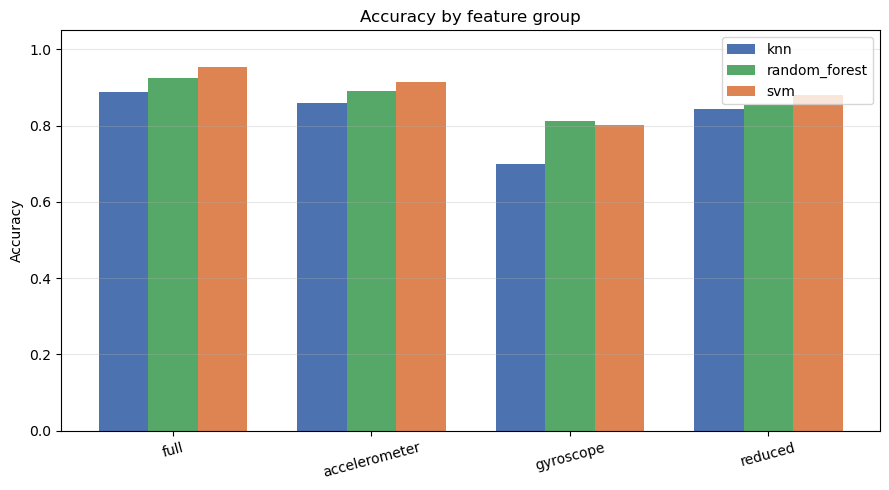

In [4]:
V.plot_group_comparison(m, C.FIGURES_DIR / "feature_group_comparison.png")
plt.show()

**Observations**
- **Accelerometer** features alone (350) are far more informative than **gyroscope** features
  alone (213) for every model - acceleration carries most of the activity signal.
- The **reduced** 50-feature subset keeps most of the accuracy of the full 561 features, so a
  much smaller model is nearly as good (useful when compute is limited).

## Which features did SelectKBest pick?

In [5]:
print("First 12 of the 50 reduced features:")
for f in groups["reduced"][:12]:
    print("  ", f)

First 12 of the 50 reduced features:
   tBodyAcc-std()-X
   tBodyAcc-mad()-X
   tBodyAcc-max()-X
   tBodyAcc-min()-X
   tBodyAcc-min()-Y
   tBodyAcc-energy()-X
   tBodyAcc-iqr()-X
   tGravityAcc-mean()-Y
   tGravityAcc-max()-Y
   tGravityAcc-min()-X
   tGravityAcc-min()-Y
   tBodyAccJerk-std()-X
